# 😊😐😢 HMM para Análisis de Sentimientos en Redes Sociales
**Actividad didáctica 2-M2 · Modelo Oculto de Markov (estándar Q1) · IU Digital de Antioquia**

Estudiante: ciro antonio carrillo mendoza

- **Estados ocultos (S):** Sentimiento Positivo · Neutral · Negativo
- **Observaciones (V):** Palabra Alegre · Normal · Triste
- **Parámetros λ = (A, B, π):** exactamente los del prompt original (no se modifican en el escenario E1).

> 🧭 **Cómo leer este notebook.**
> Las secciones **1–8 son el escenario original del prompt**. Las secciones **9–11 son la extensión que exige la actividad** (≥ 3 escenarios, sensibilidad, aprendizaje) y no alteran el caso base.

## 🗺️ Trazabilidad 1 · Requisitos del prompt → celdas

| # | Requisito del prompt | Sección |
|---|---|---|
| 1 | Clase HMM para análisis de sentimientos | 3 |
| 2 | Simular 30 publicaciones/tweets | 5 |
| 3 | Palabras ejemplo por categoría (feliz, genial, mal, triste…) | 4 |
| 4a | Timeline de sentimientos con emojis 😊😐😢 | 7 · Fig. 1 |
| 4b | Nube de palabras simulada por sentimiento | 7 · Fig. 2 |
| 4c | Gráfico de evolución temporal del sentimiento | 7 · Fig. 3 |
| 5 | Métricas: % de cada sentimiento, volatilidad, rachas más largas | 6 |
| 6 | Detector de cambios bruscos | 6 |
| 7 | "Tweets" simulados con las palabras observadas | 4 y 5 |
| 8 | Análisis de tendencia (¿mejora o empeora?) | 6 |
| 9 | Pie chart de distribución de sentimientos | 7 · Fig. 4 |
| — | Visualmente atractivo, emojis y colores, ejecutable en Colab | todo el notebook |

## 🗺️ Trazabilidad 2 · Rúbrica de la Actividad 2-M2 → evidencia

| Criterio (pts) | Dónde se evidencia |
|---|---|
| Comprensión conceptual del HMM (20) | Sección 2 (S, V, A, B, π) · Sección 3 (Forward, Viterbi, Baum-Welch) · Sección 3b (verificación contra enumeración exhaustiva) |
| Formulación y pertinencia del problema (15) | Celda de contexto (este encabezado) y Sección 2 |
| Probabilidades iniciales, A y B (15) | Sección 2 (validación de filas-estocásticas, mapas de calor) |
| Respuesta a todos los interrogantes P1–P3 (10) | Sección 12 (cada pregunta ligada a una salida concreta) |
| Resultados de simulación (20) | Secciones 5–11 (secuencias, tablas, figuras, CSV) |
| Video de sustentación (10) | Fuera del notebook · guion en el README |
| Repositorio GitHub (10) | Sección 11 exporta CSV, figuras y `entorno.txt` |

## 🗺️ Trazabilidad 3 · "Resultados y análisis exigidos" del documento de la actividad

| Exigencia | Sección |
|---|---|
| ≥ 3 escenarios comparados | 9 (E1–E4) |
| Media, desv. est., mín, máx e IC 95 % por escenario | 9 · Tabla de resumen |
| ≥ 1 tabla y ≥ 2 figuras de calidad publicable (300 dpi) | 9 y 10 |
| Reproducibilidad: semillas fijas + versiones del entorno | 1 y 11 |
| Responder cada pregunta de investigación con evidencia | 12 |

In [ ]:
# ============ 1. ENTORNO Y SEMILLAS ============
import sys, platform, random, itertools, os, warnings, subprocess
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Arc, Patch
import scipy
from scipy import stats
try:
    import wordcloud
except ImportError:                       # en Colab ya viene instalada; esto es solo respaldo
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wordcloud"]); import wordcloud
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)                  # semillas globales
OUT = "resultados"; os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})

def savefig(name):                                       # figuras a 300 dpi (exigencia Q1)
    plt.savefig(f"{OUT}/{name}.png", dpi=300, bbox_inches="tight")

def show(df):                                            # tabla bonita en Colab, texto en consola
    try:
        from IPython.display import display; display(df)
    except Exception:
        print(df.to_string())

ENV = {"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scipy": scipy.__version__, "matplotlib": matplotlib.__version__, "wordcloud": wordcloud.__version__, "SEED": SEED}
print("🔧 Entorno")
for k, v in ENV.items(): print(f"   {k:11s}: {v}")

🔧 Entorno
   Python     : 3.13.18
   numpy      : 2.4.6
   pandas     : 2.2.3
   scipy      : 1.16.3
   matplotlib : 3.10.0
   wordcloud  : 1.9.6
   SEED       : 42


## 2 · Modelo formal λ = (S, V, A, B, π)
Un HMM separa un proceso **oculto** (el sentimiento, con dependencia de primer orden: propiedad de Markov) de un proceso **observable** (las palabras).
`A[i,j] = P(z_{t+1}=j | z_t=i)` · `B[j,k] = P(o_t=k | z_t=j)` · `π[i] = P(z_1=i)`.
Los valores son **los del prompt**; la celda valida que cada fila sume 1 (criterio de rúbrica: matrices completas y coherentes).

✅ Modelo válido: A y B filas-estocásticas, π suma 1

           Positivo  Neutral  Negativo
A: de \ a                             
Positivo        0.6      0.3       0.1
Neutral         0.3      0.4       0.3
Negativo        0.1      0.3       0.6

                     Alegre  Normal  Triste
B: estado \ palabra                        
Positivo                0.7     0.2     0.1
Neutral                 0.2     0.6     0.2
Negativo                0.1     0.2     0.7

π = {'Positivo': np.float64(0.4), 'Neutral': np.float64(0.4), 'Negativo': np.float64(0.2)}


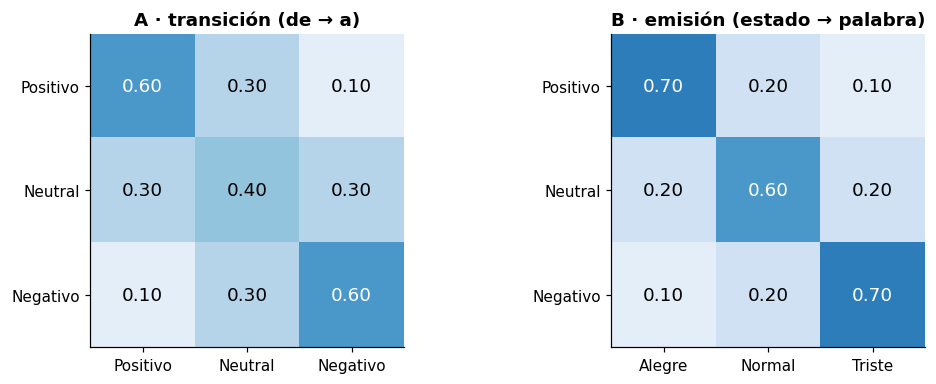

In [ ]:
# ============ 2. MODELO FORMAL  λ = (A, B, π) ============
STATES = ["Sentimiento Positivo", "Sentimiento Neutral", "Sentimiento Negativo"]
OBS    = ["Palabra Alegre", "Palabra Normal", "Palabra Triste"]
SHORT  = ["Positivo", "Neutral", "Negativo"]
EMOJI  = ["😊", "😐", "😢"]
COLORS = ["#2ecc71", "#f1c40f", "#e74c3c"]
SCORE  = np.array([1, 0, -1])                       # puntaje numérico del sentimiento (para tendencia)

A0  = np.array([[0.6, 0.3, 0.1],
                [0.3, 0.4, 0.3],
                [0.1, 0.3, 0.6]])
B0  = np.array([[0.7, 0.2, 0.1],
                [0.2, 0.6, 0.2],
                [0.1, 0.2, 0.7]])
PI0 = np.array([0.4, 0.4, 0.2])

def check_stochastic(A, B, pi):
    assert np.all(A >= 0) and np.all(B >= 0) and np.all(pi >= 0), "Probabilidades negativas"
    assert np.allclose(A.sum(1), 1) and np.allclose(B.sum(1), 1) and np.isclose(pi.sum(), 1), "Filas no suman 1"

check_stochastic(A0, B0, PI0)
print("✅ Modelo válido: A y B filas-estocásticas, π suma 1\n")
print(pd.DataFrame(A0, index=SHORT, columns=SHORT).round(2).rename_axis("A: de \\ a"))
print(); print(pd.DataFrame(B0, index=SHORT, columns=["Alegre", "Normal", "Triste"]).round(2).rename_axis("B: estado \\ palabra"))
print("\nπ =", dict(zip(SHORT, PI0)))

# Mapas de calor de A y B (apoyo visual a la explicación conceptual)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, M, cols, ttl in [(axs[0], A0, SHORT, "A · transición (de → a)"), (axs[1], B0, ["Alegre", "Normal", "Triste"], "B · emisión (estado → palabra)")]:
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white" if M[i, j] > .5 else "black", fontsize=12)
    ax.set_xticks(range(3)); ax.set_xticklabels(cols); ax.set_yticks(range(3)); ax.set_yticklabels(SHORT)
    ax.set_title(ttl, fontweight="bold"); ax.grid(False)
plt.tight_layout(); savefig("fig0_matrices"); plt.show()

## 3 · Clase HMM (Forward · Viterbi · Baum-Welch)
Los **tres problemas clásicos** del HMM (Rabiner, 1989):

| Problema | Algoritmo | Método de la clase |
|---|---|---|
| Evaluación: ¿qué tan probable es la secuencia? `P(O\|λ)` | Forward (con escalado) | `forward`, `loglik` |
| Decodificación: ¿qué estados la generaron? | Viterbi (en log) y posterior suavizado γ | `viterbi`, `posterior` |
| Aprendizaje: ¿qué λ explica los datos? | Baum-Welch (EM) | `baum_welch` |

Además `posterior` calcula la **volatilidad esperada** a partir de ξ_t(i,j): es la estimación de cambios de sentimiento que un analista sí puede obtener viendo solo palabras.

In [ ]:
# ============ 3. CLASE HMM ============
def _fb(A, B, pi, O):
    """Forward-backward escalado, vectorizado sobre S secuencias de igual longitud T. O: (S, T)."""
    S, T = O.shape; N = len(pi)
    alpha = np.zeros((S, T, N)); c = np.zeros((S, T))
    alpha[:, 0] = pi * B[:, O[:, 0]].T
    c[:, 0] = alpha[:, 0].sum(1); alpha[:, 0] /= c[:, 0, None]
    for t in range(1, T):
        alpha[:, t] = (alpha[:, t-1] @ A) * B[:, O[:, t]].T
        c[:, t] = alpha[:, t].sum(1); alpha[:, t] /= c[:, t, None]
    beta = np.ones((S, T, N))
    for t in range(T-2, -1, -1):
        beta[:, t] = ((B[:, O[:, t+1]].T * beta[:, t+1]) @ A.T) / c[:, t+1, None]
    return alpha, beta, c

class HMM:
    """HMM discreto λ=(A,B,π). Estados ocultos S (sentimiento), observaciones V (palabras)."""
    def __init__(self, A, B, pi, seed=None):
        self.A, self.B, self.pi = np.array(A, float), np.array(B, float), np.array(pi, float)
        check_stochastic(self.A, self.B, self.pi)
        self.N, self.M = self.B.shape
        self.rng = np.random.default_rng(seed)

    # --- Generación: z1~π, z_t~A[z_{t-1}], o_t~B[z_t] ---
    def sample(self, T):
        z, o = np.zeros(T, int), np.zeros(T, int)
        z[0] = self.rng.choice(self.N, p=self.pi)
        for t in range(T):
            if t > 0: z[t] = self.rng.choice(self.N, p=self.A[z[t-1]])
            o[t] = self.rng.choice(self.M, p=self.B[z[t]])
        return z, o

    # --- Problema 1 · Evaluación (Forward) ---
    def forward(self, o):
        alpha, _, c = _fb(self.A, self.B, self.pi, np.asarray(o)[None])
        return alpha[0], np.log(c[0]).sum()            # P(z_t | o_1:t) filtrada, log P(O|λ)

    def loglik(self, O):
        _, _, c = _fb(self.A, self.B, self.pi, np.atleast_2d(O)); return np.log(c).sum()

    # --- Problema 2 · Decodificación (Viterbi, en escala log) ---
    def viterbi(self, o):
        T = len(o)
        with np.errstate(divide="ignore"):
            lA, lB, lpi = np.log(self.A), np.log(self.B), np.log(self.pi)
        delta, psi = np.zeros((T, self.N)), np.zeros((T, self.N), int)
        delta[0] = lpi + lB[:, o[0]]
        for t in range(1, T):
            s = delta[t-1][:, None] + lA
            psi[t] = s.argmax(0); delta[t] = s.max(0) + lB[:, o[t]]
        path = np.zeros(T, int); path[-1] = delta[-1].argmax()
        for t in range(T-2, -1, -1): path[t] = psi[t+1, path[t+1]]
        return path, delta[-1].max()

    # --- Decodificación alternativa: posterior suavizado γ_t(i)=P(z_t=i | o_1:T) y volatilidad esperada ---
    def posterior(self, o):
        o = np.asarray(o); a, b, c = (x[0] for x in _fb(self.A, self.B, self.pi, o[None]))
        gamma = a * b; gamma /= gamma.sum(1, keepdims=True)
        xi = a[:-1, :, None] * self.A[None] * (self.B[:, o[1:]].T * b[1:])[:, None, :] / c[1:, None, None]
        vol_esperada = 1 - xi.trace(axis1=1, axis2=2).mean()      # E[proporción de cambios de estado | O]
        return gamma, vol_esperada

    def decode_posterior(self, o):
        return self.posterior(o)[0].argmax(1)

def baum_welch(O, A, B, pi, n_iter=300, tol=1e-7):
    """Problema 3 · Aprendizaje (EM / Baum-Welch) sobre varias secuencias de igual longitud. Devuelve (HMM, historial log-verosimilitud)."""
    O = np.atleast_2d(O); N, M = B.shape; hist = []
    for it in range(n_iter):
        alpha, beta, c = _fb(A, B, pi, O)
        hist.append(np.log(c).sum())
        if it > 0 and abs(hist[-1] - hist[-2]) < tol: break
        gamma = alpha * beta
        xi = alpha[:, :-1, :, None] * A[None, None] * (B[:, O[:, 1:]].transpose(1, 2, 0) * beta[:, 1:])[:, :, None, :] / c[:, 1:, None, None]
        pi = gamma[:, 0].mean(0)
        A = xi.sum((0, 1)) / gamma[:, :-1].sum((0, 1))[:, None]
        B = np.stack([(gamma * (O == k)[:, :, None]).sum((0, 1)) for k in range(M)], 1) / gamma.sum((0, 1))[:, None]
    else:
        hist.append(np.log(_fb(A, B, pi, O)[2]).sum())
    return HMM(A, B, pi), np.array(hist)
print("✅ Clase HMM lista: sample · forward · viterbi · posterior · baum_welch")

✅ Clase HMM lista: sample · forward · viterbi · posterior · baum_welch


### 3b · Verificación de corrección (evidencia de rigor)
Forward y Viterbi se comparan contra **enumeración exhaustiva** de las 3⁵ = 243 trayectorias, y la distribución estacionaria se contrasta con una simulación larga.

In [ ]:
# ============ 3b. VERIFICACIÓN CONTRA ENUMERACIÓN EXHAUSTIVA ============
def brute_force(h, o):
    best, total, best_path = -1, 0.0, None
    for z in itertools.product(range(3), repeat=len(o)):
        p = h.pi[z[0]] * h.B[z[0], o[0]]
        for t in range(1, len(o)): p *= h.A[z[t-1], z[t]] * h.B[z[t], o[t]]
        total += p
        if p > best: best, best_path = p, np.array(z)
    return total, best_path

h_chk = HMM(A0, B0, PI0, seed=123); _, o_chk = h_chk.sample(5)
tot, bp = brute_force(h_chk, o_chk)
assert np.isclose(np.exp(h_chk.forward(o_chk)[1]), tot), "Forward ≠ enumeración"
assert np.array_equal(h_chk.viterbi(o_chk)[0], bp), "Viterbi ≠ enumeración"
print(f"✅ Forward = suma exhaustiva ({tot:.6f})  |  ✅ Viterbi = trayectoria de máxima probabilidad {bp.tolist()}")

# Distribución estacionaria π* (π* A = π*) y volatilidad teórica 1 − Σ π*_i a_ii
w, v = np.linalg.eig(A0.T); pi_star = np.real(v[:, np.argmax(np.real(w))]); pi_star /= pi_star.sum()
zl = HMM(A0, B0, PI0, seed=SEED + 7).sample(100_000)[0]
print(f"✅ π* teórica = {pi_star.round(4)} | frecuencia empírica (100 000 pasos) = {(np.bincount(zl) / len(zl)).round(4)}")
print(f"✅ Volatilidad teórica E1 = {1 - pi_star @ np.diag(A0):.3f}")

✅ Forward = suma exhaustiva (0.005907)  |  ✅ Viterbi = trayectoria de máxima probabilidad [0, 0, 1, 1, 2]
✅ π* teórica = [0.3333 0.3333 0.3333] | frecuencia empírica (100 000 pasos) = [0.3339 0.3308 0.3353]
✅ Volatilidad teórica E1 = 0.467


## 4 · Palabras ejemplo y "tweets" simulados
El modelo trabaja con la **categoría observada** (Alegre / Normal / Triste); el texto del tweet es ilustrativo: se elige una palabra del léxico de esa categoría y una plantilla.

In [ ]:
# ============ 4. PALABRAS Y TWEETS SIMULADOS ============
LEXICON = {0: ["feliz", "genial", "increíble", "excelente", "fantástico", "maravilloso"],   # Palabra Alegre
           1: ["normal", "regular", "tranquilo", "común", "ok", "así así"],                  # Palabra Normal
           2: ["triste", "mal", "horrible", "pésimo", "terrible", "deprimente"]}             # Palabra Triste
TEMPLATES = ["Hoy todo me parece {w}", "Mi día fue {w}", "La verdad estoy {w}", "Qué situación tan {w}",
             "Mi semana ha sido {w}", "Sinceramente, {w}"]
HASHTAGS = ["#vida", "#hoy", "#mood", "#semana", "#redes"]

def generate_tweets(o, rng):
    words = [rng.choice(LEXICON[k]) for k in o]
    tweets = [f"{rng.choice(TEMPLATES).format(w=w)} {rng.choice(HASHTAGS)}" for w in words]
    return words, tweets

In [ ]:
# ============ 5. SIMULACIÓN BASE: 30 PUBLICACIONES ============
T = 30
hmm = HMM(A0, B0, PI0, seed=SEED)
z, o = hmm.sample(T)                                     # z: sentimiento oculto real · o: palabra observada
words, tweets = generate_tweets(o, np.random.default_rng(SEED))
z_hat, _ = hmm.viterbi(o)                                # estimación con Viterbi (solo ve palabras)
gamma, vol_exp = hmm.posterior(o)                        # posterior suavizado + volatilidad esperada
z_post = gamma.argmax(1)
alpha, loglik = hmm.forward(o)                           # P(z_t | o_1:t) y log P(O|λ)

df = pd.DataFrame({"t": np.arange(1, T+1), "estado_real": [SHORT[i] for i in z],
                   "observacion": [OBS[i] for i in o], "palabra": words,
                   "estado_viterbi": [SHORT[i] for i in z_hat], "estado_posterior": [SHORT[i] for i in z_post],
                   "P(pos|o1:T)": gamma[:, 0].round(3), "P(neu|o1:T)": gamma[:, 1].round(3), "P(neg|o1:T)": gamma[:, 2].round(3),
                   "tweet": tweets})
print(f"🐦 Se simularon {T} tweets | log P(O|λ) = {loglik:.3f} | precisión Viterbi = {(z == z_hat).mean():.1%} | precisión posterior = {(z == z_post).mean():.1%}\n")
for t in range(T):
    print(f"{t+1:02d} {EMOJI[z[t]]} {tweets[t]:42s} (oculto: {SHORT[z[t]]:8s} | Viterbi: {SHORT[z_hat[t]]})")

🐦 Se simularon 30 tweets | log P(O|λ) = -33.001 | precisión Viterbi = 66.7% | precisión posterior = 66.7%

01 😐 La verdad estoy normal #hoy                (oculto: Neutral  | Viterbi: Neutral)
02 😢 Hoy todo me parece terrible #mood          (oculto: Negativo | Viterbi: Negativo)
03 😊 Sinceramente, pésimo #vida                 (oculto: Positivo | Viterbi: Negativo)
04 😐 Sinceramente, tranquilo #redes             (oculto: Neutral  | Viterbi: Neutral)
05 😊 Mi día fue increíble #semana               (oculto: Positivo | Viterbi: Neutral)
06 😊 Hoy todo me parece deprimente #semana      (oculto: Positivo | Viterbi: Negativo)
07 😐 Mi semana ha sido triste #hoy              (oculto: Neutral  | Viterbi: Negativo)
08 😐 Hoy todo me parece ok #redes               (oculto: Neutral  | Viterbi: Neutral)
09 😐 La verdad estoy genial #redes              (oculto: Neutral  | Viterbi: Neutral)
10 😢 Mi semana ha sido triste #semana           (oculto: Negativo | Viterbi: Negativo)
11 😢 Mi semana ha sido pésim

In [ ]:
# ============ 6. MÉTRICAS, DETECTOR DE CAMBIOS BRUSCOS Y TENDENCIA ============
def longest_runs(z, n=3):
    out = np.zeros(n, int)
    for k, g in itertools.groupby(z): out[k] = max(out[k], len(list(g)))
    return out

def abrupt_changes(path):
    """Cambio brusco = salto Positivo↔Negativo en un solo paso (|Δ puntaje| = 2). Devuelve los índices t donde ocurre."""
    return np.where(np.abs(np.diff(SCORE[path])) == 2)[0] + 1

def trend(score, alpha_level=.05):
    r = stats.linregress(np.arange(len(score)), score)
    label = "📈 MEJORA" if (r.pvalue < alpha_level and r.slope > 0) else \
            "📉 EMPEORA" if (r.pvalue < alpha_level and r.slope < 0) else "➖ ESTABLE (sin tendencia significativa)"
    return r, label

vol = lambda s: np.mean(s[1:] != s[:-1])                 # volatilidad = proporción de transiciones con cambio de estado

pct = np.bincount(z, minlength=3) / T * 100
runs = longest_runs(z)
det, real = abrupt_changes(z_hat), abrupt_changes(z)
tp = len(set(det) & set(real))
r_real, lab_real = trend(SCORE[z])                        # tendencia sobre estados reales (referencia)
exp_score = gamma @ SCORE                                 # puntaje esperado dado SOLO las palabras (lo que vería un analista)
r_est = stats.linregress(np.arange(T), exp_score)

print("📊 MÉTRICAS (simulación base)")
for i in range(3): print(f"   {EMOJI[i]} {SHORT[i]:9s}: {pct[i]:5.1f} %   | racha más larga: {runs[i]}")
print(f"   🌪️  Volatilidad real: {vol(z):.2%} ({int(round(vol(z)*(T-1)))} cambios de {T-1} transiciones)")
print(f"       Estimada con Viterbi: {vol(z_hat):.2%} | con posterior esperada (ξ): {vol_exp:.2%}   (en una sola corrida varía; el sesgo promedio está en la Tabla C)")
print(f"   ⚡ Cambios bruscos detectados (Viterbi, sin ver estados reales): "
      f"{[f'{SHORT[z_hat[i-1]]}→{SHORT[z_hat[i]]} en t={i+1}' for i in det] or 'ninguno'}")
print(f"   ⚡ Cambios bruscos reales: {[f't={i+1}' for i in real] or 'ninguno'}  →  aciertos {tp}, falsos positivos {len(det)-tp}, omitidos {len(real)-tp}")
print(f"   🔎 Tendencia (estados reales):          pendiente = {r_real.slope:+.4f}/tweet, p = {r_real.pvalue:.3f} → {lab_real}")
print(f"   🔎 Tendencia (puntaje esperado, observable): pendiente = {r_est.slope:+.4f}/tweet (solo descriptiva: el puntaje esperado está autocorrelacionado y su p-valor sería engañoso)")
h1, h2 = SCORE[z][:T//2].mean(), SCORE[z][T//2:].mean()
print(f"   🔎 Sentimiento medio 1ª mitad = {h1:+.2f} | 2ª mitad = {h2:+.2f}  (una sola corrida de 30 puntos no es concluyente → sección 9)")

📊 MÉTRICAS (simulación base)
   😊 Positivo :  23.3 %   | racha más larga: 3
   😐 Neutral  :  43.3 %   | racha más larga: 3
   😢 Negativo :  33.3 %   | racha más larga: 5
   🌪️  Volatilidad real: 58.62% (17 cambios de 29 transiciones)
       Estimada con Viterbi: 62.07% | con posterior esperada (ξ): 52.32%   (en una sola corrida varía; el sesgo promedio está en la Tabla C)
   ⚡ Cambios bruscos detectados (Viterbi, sin ver estados reales): ['Negativo→Positivo en t=30']
   ⚡ Cambios bruscos reales: ['t=3']  →  aciertos 0, falsos positivos 1, omitidos 1
   🔎 Tendencia (estados reales):          pendiente = -0.0051/tweet, p = 0.755 → ➖ ESTABLE (sin tendencia significativa)
   🔎 Tendencia (puntaje esperado, observable): pendiente = +0.0223/tweet (solo descriptiva: el puntaje esperado está autocorrelacionado y su p-valor sería engañoso)
   🔎 Sentimiento medio 1ª mitad = -0.20 | 2ª mitad = +0.00  (una sola corrida de 30 puntos no es concluyente → sección 9)


## 7 · Visualizaciones del caso base
Las caritas del timeline se **dibujan con matplotlib** (no dependen de fuentes de emojis, que en Colab/servidores a veces salen como cuadros o en blanco y negro).

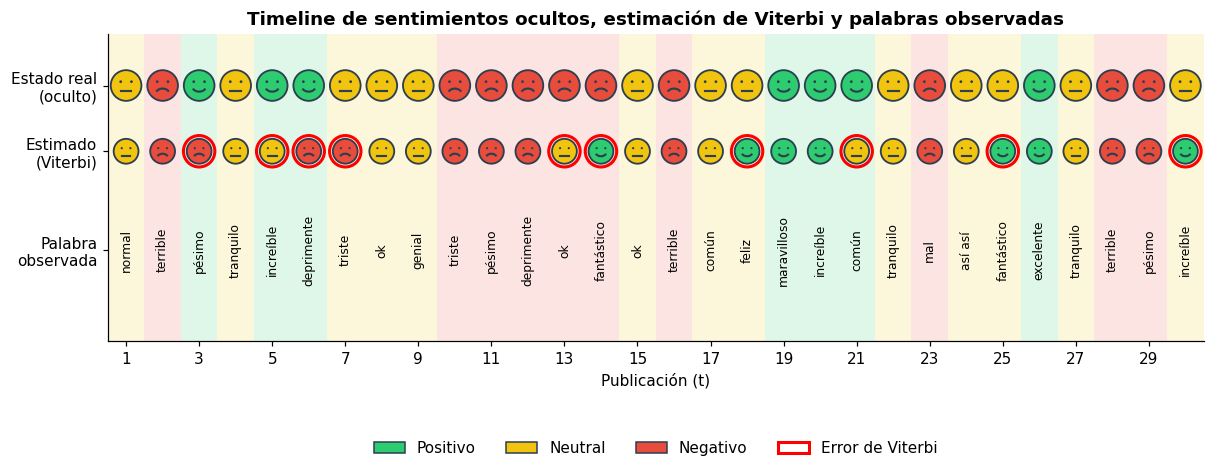

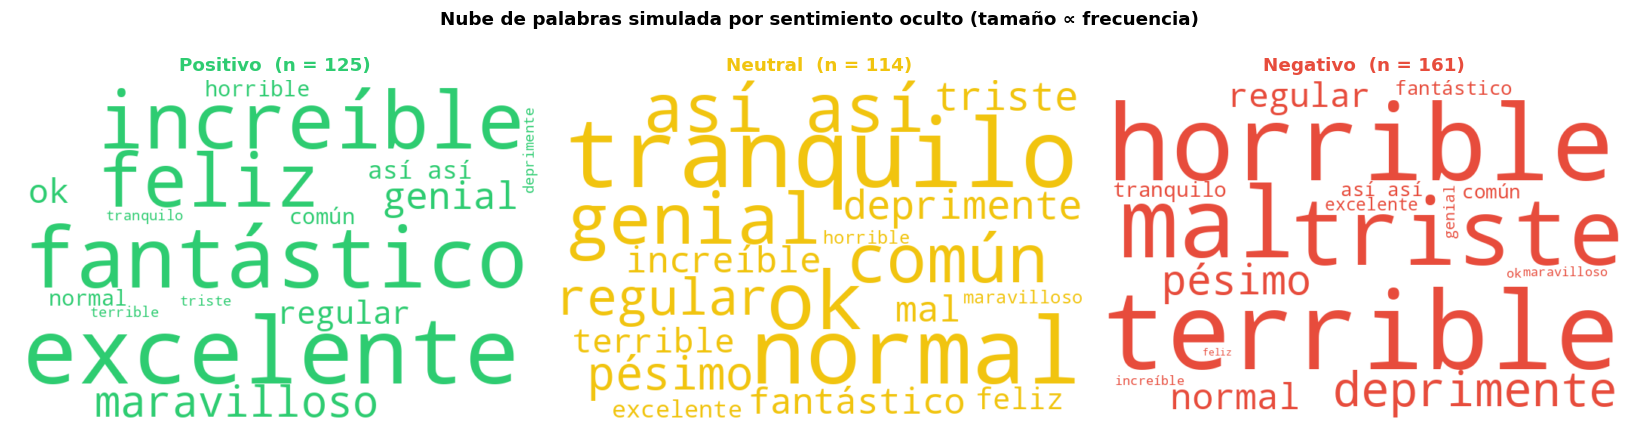

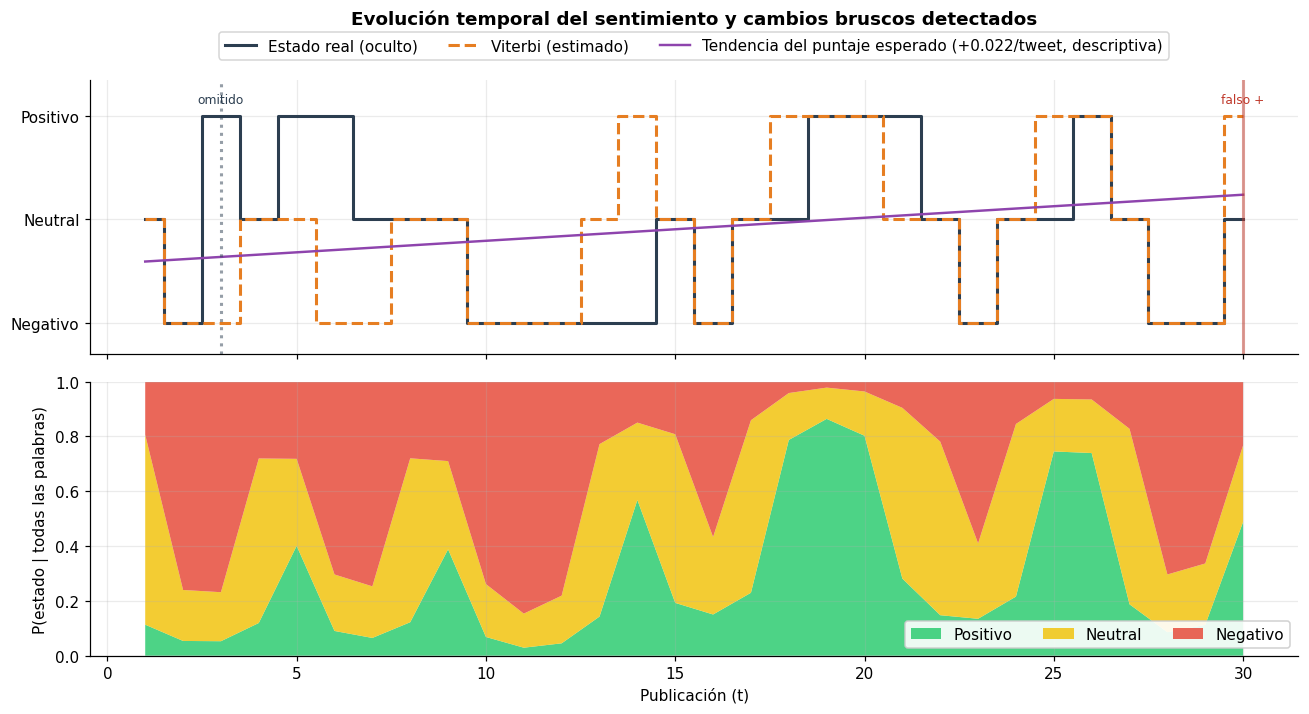

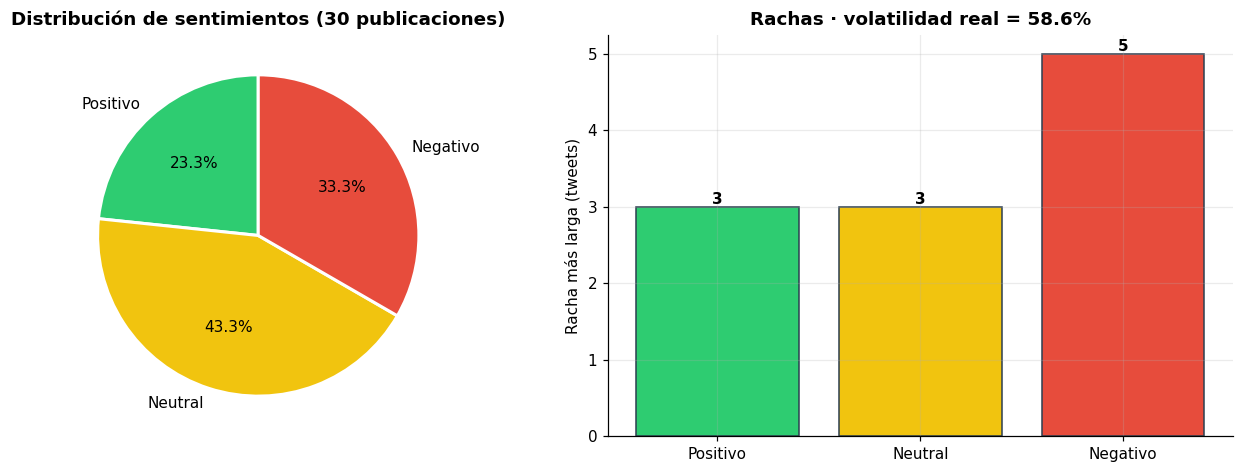

In [ ]:
# ============ 7. VISUALIZACIONES ============
def face(ax, x, y, kind, r, color):
    """Dibuja una carita: kind 0 = 😊, 1 = 😐, 2 = 😢."""
    ax.add_patch(Circle((x, y), r, fc=color, ec="#2c3e50", lw=1.2, zorder=3))
    for dx in (-.35*r, .35*r): ax.add_patch(Circle((x+dx, y+.25*r), .09*r, fc="#2c3e50", zorder=4))
    if kind == 0:   ax.add_patch(Arc((x, y-.05*r), .9*r, .7*r, theta1=200, theta2=340, lw=1.4, color="#2c3e50", zorder=4))
    elif kind == 2: ax.add_patch(Arc((x, y-.55*r), .9*r, .7*r, theta1=20, theta2=160, lw=1.4, color="#2c3e50", zorder=4))
    else:           ax.plot([x-.35*r, x+.35*r], [y-.35*r]*2, lw=1.4, color="#2c3e50", zorder=4)

# --- Fig 1: timeline con caritas (estado real y Viterbi) y palabras observadas ---
fig, ax = plt.subplots(figsize=(15, 4.4))
for t in range(T):
    ax.axvspan(t+.5, t+1.5, color=COLORS[z[t]], alpha=.15, lw=0)
    face(ax, t+1, 7.0, z[t], .42, COLORS[z[t]])
    face(ax, t+1, 5.2, z_hat[t], .34, COLORS[z_hat[t]])
    if z_hat[t] != z[t]: ax.add_patch(Circle((t+1, 5.2), .43, fill=False, ec="red", lw=2, zorder=5))
    ax.text(t+1, 2.5, words[t], rotation=90, ha="center", va="center", fontsize=8)
ax.set_xlim(.5, T+.5); ax.set_ylim(0, 8.4); ax.set_aspect("equal", adjustable="box"); ax.grid(False)
ax.set_yticks([7.0, 5.2, 2.5]); ax.set_yticklabels(["Estado real\n(oculto)", "Estimado\n(Viterbi)", "Palabra\nobservada"])
ax.set_xticks(range(1, T+1, 2)); ax.set_xlabel("Publicación (t)")
ax.legend(handles=[Patch(fc=COLORS[i], ec="#2c3e50", label=SHORT[i]) for i in range(3)] +
          [Circle((0, 0), fill=False, ec="red", lw=2, label="Error de Viterbi")], ncol=4, loc="upper center", bbox_to_anchor=(.5, -.28), frameon=False)
ax.set_title("Timeline de sentimientos ocultos, estimación de Viterbi y palabras observadas", fontweight="bold")
plt.tight_layout(); savefig("fig1_timeline"); plt.show()

# --- Fig 2: nube de palabras simulada por sentimiento oculto (muestra mayor n=400 para frecuencias estables) ---
big = HMM(A0, B0, PI0, seed=SEED + 1); zb, ob = big.sample(400)
wb, _ = generate_tweets(ob, np.random.default_rng(SEED))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for i, ax in enumerate(axes):
    freq = Counter(w for w, s in zip(wb, zb) if s == i)
    wc = WordCloud(width=700, height=450, background_color="white", random_state=SEED, prefer_horizontal=.95,
                   color_func=lambda *a, c=COLORS[i], **k: c).generate_from_frequencies(freq)
    ax.imshow(wc.to_array(), interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"{SHORT[i]}  (n = {sum(freq.values())})", fontweight="bold", color=COLORS[i])
fig.suptitle("Nube de palabras simulada por sentimiento oculto (tamaño ∝ frecuencia)", fontweight="bold")
plt.tight_layout(); savefig("fig2_nubes"); plt.show()

# --- Fig 3: evolución temporal (real vs Viterbi) + posterior suavizado ---
fig, axes = plt.subplots(2, 1, figsize=(12, 6.6), sharex=True)
t_ = np.arange(1, T+1)
axes[0].step(t_, SCORE[z], where="mid", color="#2c3e50", lw=2, label="Estado real (oculto)")
axes[0].step(t_, SCORE[z_hat], where="mid", color="#e67e22", lw=2, ls="--", label="Viterbi (estimado)")
axes[0].plot(t_, r_est.intercept + r_est.slope*np.arange(T), color="#8e44ad", lw=1.6, label=f"Tendencia del puntaje esperado ({r_est.slope:+.3f}/tweet, descriptiva)")
for i in det:
    ok = i in real
    axes[0].axvline(i+1, color="#27ae60" if ok else "#c0392b", alpha=.5, lw=2)
    axes[0].text(i+1, 1.12, "acierto" if ok else "falso +", color="#27ae60" if ok else "#c0392b", ha="center", fontsize=8)
for i in set(real) - set(det):
    axes[0].axvline(i+1, color="#2c3e50", alpha=.5, lw=2, ls=":"); axes[0].text(i+1, 1.12, "omitido", color="#2c3e50", ha="center", fontsize=8)
axes[0].set_yticks([-1, 0, 1]); axes[0].set_yticklabels(["Negativo", "Neutral", "Positivo"]); axes[0].set_ylim(-1.3, 1.35)
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.2)); axes[0].set_title("Evolución temporal del sentimiento y cambios bruscos detectados", fontweight="bold", pad=36)
axes[1].stackplot(t_, gamma.T, colors=COLORS, labels=SHORT, alpha=.85)
axes[1].set_ylabel("P(estado | todas las palabras)"); axes[1].set_xlabel("Publicación (t)"); axes[1].set_ylim(0, 1)
axes[1].legend(ncol=3, loc="lower right", framealpha=.9)
plt.tight_layout(); savefig("fig3_evolucion"); plt.show()

# --- Fig 4: pie chart de distribución + rachas más largas ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].pie(pct, labels=SHORT, colors=COLORS, autopct="%1.1f%%", startangle=90, wedgeprops=dict(edgecolor="white", linewidth=2))
axes[0].set_title("Distribución de sentimientos (30 publicaciones)", fontweight="bold")
b = axes[1].bar(SHORT, runs, color=COLORS, edgecolor="#2c3e50")
axes[1].bar_label(b, fontweight="bold"); axes[1].set_ylabel("Racha más larga (tweets)")
axes[1].set_title(f"Rachas · volatilidad real = {vol(z):.1%}", fontweight="bold")
plt.tight_layout(); savefig("fig4_pie_rachas"); plt.show()

---
# Extensión exigida por la actividad (secciones 9–11)
El prompt original describe **un solo modelo y 30 publicaciones**. La actividad 2-M2 además exige **≥ 3 escenarios**, estadísticos con IC 95 %, sensibilidad (P3) y evidencia de reproducibilidad.
**E1 es el modelo del prompt, sin cambios.** E2–E4 modifican una sola cosa a la vez para ver su efecto.

| Escenario | Qué cambia respecto de E1 | Pregunta que responde |
|---|---|---|
| E1 Base | Nada (prompt original) | Referencia |
| E2 Persistente | Diagonal de A = 0.85 | ¿Qué hace la inercia emocional (A)? |
| E3 Emisión ruidosa | B con diagonal 0.40/0.50/0.40 | ¿Qué hace la claridad de las palabras (B)? |
| E4 Sesgo negativo | A y π inclinados a lo negativo | ¿Qué hace un entorno negativo? |

✅ Reproducibilidad verificada: la réplica 0 de E1 se regenera idéntica con su semilla [42, 0, 0]

📋 Tabla A · Resumen estadístico (1000 réplicas × 30 tweets por escenario)


,escenario,métrica,media,desv_est,mín,máx,IC95_inf,IC95_sup
0,E1 Base,pct_pos,34.480,13.377,0.000,80.000,33.650,35.310
1,E1 Base,pct_neg,32.403,13.677,0.000,76.667,31.555,33.252
2,E1 Base,volatilidad,0.466,0.098,0.138,0.759,0.460,0.472
3,E1 Base,cambios_bruscos,1.971,1.411,0.000,8.000,1.883,2.059
4,E1 Base,racha_pos,4.514,2.195,0.000,17.000,4.378,4.650
5,E1 Base,racha_neg,4.408,2.242,0.000,16.000,4.269,4.547
6,E1 Base,pendiente,-0.003,0.027,-0.077,0.075,-0.005,-0.001
7,E1 Base,precision_viterbi,0.651,0.100,0.267,0.933,0.644,0.657
8,E2 Persistente,pct_pos,31.617,23.362,0.000,100.000,30.167,33.066
9,E2 Persistente,pct_neg,28.313,21.590,0.000,100.000,26.974,29.653



📋 Tabla B · ¿El HMM aporta frente a clasificar cada palabra por separado? (precisión por paso, media [IC 95 %])


,baseline,viterbi,posterior
E1 Base,"0.664 [0.659, 0.669]","0.651 [0.644, 0.657]","0.667 [0.662, 0.673]"
E2 Persistente,"0.658 [0.652, 0.664]","0.750 [0.741, 0.760]","0.764 [0.756, 0.772]"
E3 Emisión ruidosa,"0.438 [0.432, 0.443]","0.376 [0.368, 0.384]","0.440 [0.434, 0.446]"
E4 Sesgo negativo,"0.673 [0.668, 0.679]","0.670 [0.664, 0.677]","0.685 [0.679, 0.691]"



📋 Tabla C · Volatilidad: real (no observable) vs estimadores a partir de palabras (media [IC 95 %])


,volatilidad,vol_viterbi,vol_esperada_xi
E1 Base,"0.466 [0.460, 0.472]","0.313 [0.308, 0.318]","0.466 [0.464, 0.468]"
E2 Persistente,"0.151 [0.146, 0.155]","0.060 [0.058, 0.062]","0.150 [0.148, 0.151]"
E3 Emisión ruidosa,"0.471 [0.465, 0.477]","0.028 [0.026, 0.031]","0.467 [0.467, 0.468]"
E4 Sesgo negativo,"0.424 [0.417, 0.430]","0.262 [0.256, 0.269]","0.423 [0.421, 0.426]"



🧪 Kruskal-Wallis entre escenarios:
   volatilidad        H =   2261.0  p = 1.0e-300
   precision_viterbi  H =   2079.2  p = 1.0e-300
   pct_neg            H =   1104.6  p = 3.6e-239

🧪 Mann-Whitney vs E1 (p ajustado por Holm) y tamaño de efecto δ de Cliff  (|δ|<.15 despreciable · <.33 pequeño · <.47 mediano · ≥.47 grande):


,métrica,escenario vs E1,p_Holm,δ_Cliff
0,volatilidad,E2 Persistente,0.0000,-0.9913
1,volatilidad,E3 Emisión ruidosa,0.2149,0.0318
2,volatilidad,E4 Sesgo negativo,0.0000,-0.2247
3,precision_viterbi,E2 Persistente,0.0000,0.4412
4,precision_viterbi,E3 Emisión ruidosa,0.0000,-0.8993
5,precision_viterbi,E4 Sesgo negativo,0.0000,0.1124
6,pct_neg,E2 Persistente,0.0000,-0.1819
7,pct_neg,E3 Emisión ruidosa,0.3254,0.0253
8,pct_neg,E4 Sesgo negativo,0.0000,0.7083



🧪 Wilcoxon pareado (mismas réplicas): ¿posterior > Viterbi?  ¿posterior > línea base?
   E1 Base              posterior−Viterbi = +0.017 (p=8.3e-14) | posterior−baseline = +0.003 (p=3.4e-05)
   E2 Persistente       posterior−Viterbi = +0.013 (p=2.7e-07) | posterior−baseline = +0.106 (p=6.1e-119)
   E3 Emisión ruidosa   posterior−Viterbi = +0.064 (p=6.9e-42) | posterior−baseline = +0.002 (p=1.3e-02)
   E4 Sesgo negativo    posterior−Viterbi = +0.015 (p=5.9e-18) | posterior−baseline = +0.012 (p=1.7e-12)


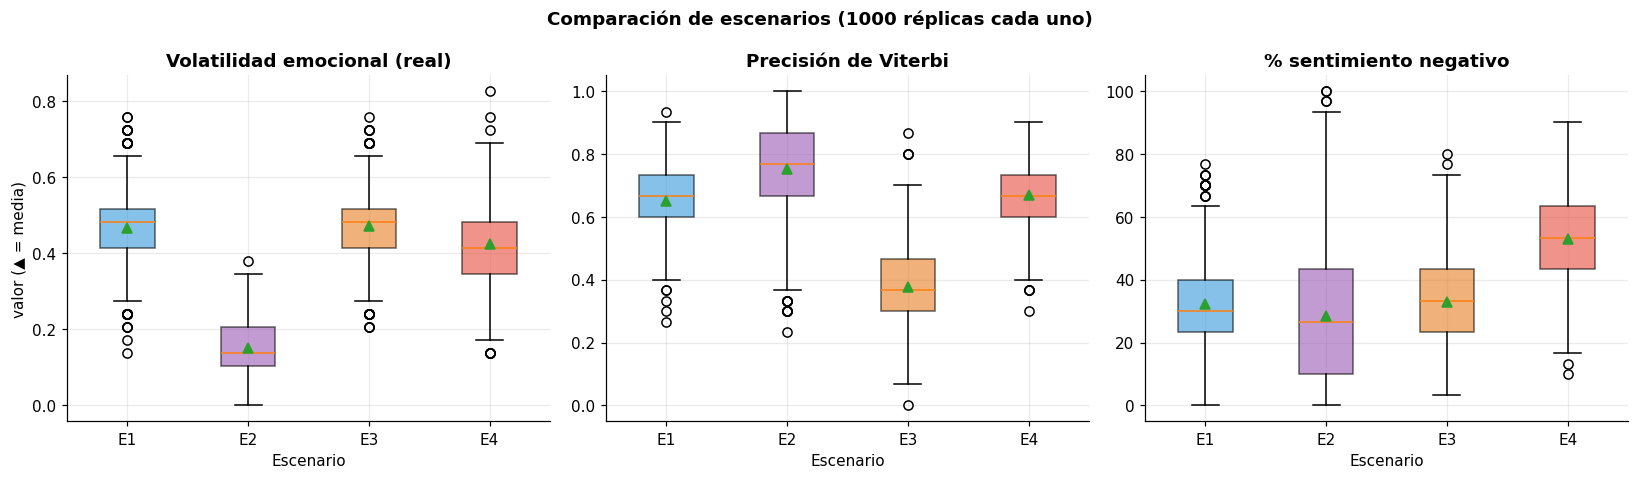

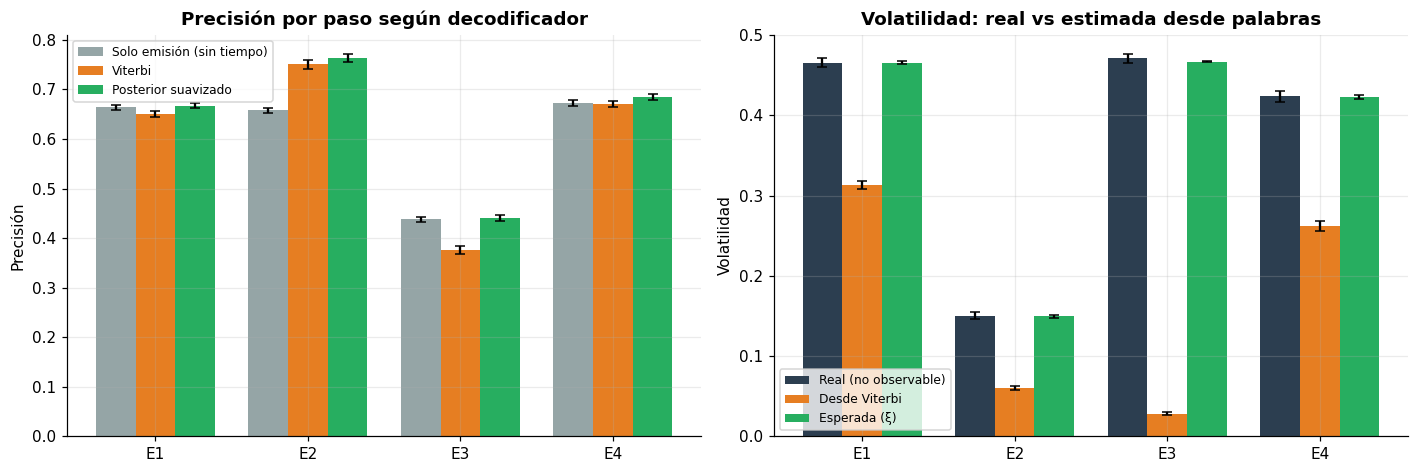

In [ ]:
# ============ 9. ESCENARIOS × 1000 RÉPLICAS (semilla fija por réplica) ============
SCENARIOS = {
    "E1 Base":           (A0, B0, PI0),
    "E2 Persistente":    (np.array([[.85, .10, .05], [.075, .85, .075], [.05, .10, .85]]), B0, PI0),
    "E3 Emisión ruidosa":(A0, np.array([[.40, .35, .25], [.25, .50, .25], [.25, .35, .40]]), PI0),
    "E4 Sesgo negativo": (np.array([[.5, .3, .2], [.2, .4, .4], [.05, .25, .70]]), B0, np.array([.1, .3, .6])),
}
for n, (A_, B_, p_) in SCENARIOS.items(): check_stochastic(A_, B_, p_)
N_RUNS = 1000

def metrics_full(h, z, o):
    """Métricas de una réplica. 'real' usa el estado oculto (solo existe en simulación); 'viterbi/posterior/xi' usan solo palabras."""
    zv = h.viterbi(o)[0]; g, vol_xi = h.posterior(o); zp = g.argmax(1); zb = h.B.argmax(0)[o]   # zb = línea base: solo emisión, sin tiempo
    p = np.bincount(z, minlength=3) / len(z) * 100; rr = longest_runs(z)
    real, det = set(abrupt_changes(z)), set(abrupt_changes(zv)); tp = len(real & det)
    return {"pct_pos": p[0], "pct_neu": p[1], "pct_neg": p[2], "volatilidad": vol(z), "vol_viterbi": vol(zv), "vol_esperada_xi": vol_xi,
            "cambios_bruscos": len(real), "racha_pos": rr[0], "racha_neu": rr[1], "racha_neg": rr[2],
            "pendiente": stats.linregress(np.arange(len(z)), SCORE[z]).slope,
            "precision_viterbi": np.mean(z == zv), "precision_posterior": np.mean(z == zp), "precision_baseline": np.mean(z == zb),
            "detector_aciertos": tp, "detector_falsos_pos": len(det) - tp, "detector_omitidos": len(real) - tp}

def run_scenario(idx, A, B, pi, n_runs=N_RUNS, T=30):
    rows = []
    for r in range(n_runs):
        h = HMM(A, B, pi, seed=[SEED, idx, r])            # semilla única y reproducible por réplica
        zz, oo = h.sample(T); rows.append(metrics_full(h, zz, oo))
    return pd.DataFrame(rows)

raw = pd.concat({name: run_scenario(i, *p) for i, (name, p) in enumerate(SCENARIOS.items())}, names=["escenario", "run"])
raw.to_csv(f"{OUT}/resultados_crudos.csv")
# Reproducibilidad exacta: repetir una réplica debe dar exactamente lo mismo
_h = HMM(*SCENARIOS["E1 Base"], seed=[SEED, 0, 0]); _z, _o = _h.sample(30)
assert metrics_full(_h, _z, _o)["precision_viterbi"] == raw.loc[("E1 Base", 0), "precision_viterbi"], "No reproducible"
print("✅ Reproducibilidad verificada: la réplica 0 de E1 se regenera idéntica con su semilla [42, 0, 0]\n")

def ci95(x):
    x = np.asarray(x); h = stats.t.ppf(.975, len(x)-1) * x.std(ddof=1) / np.sqrt(len(x)); return x.mean()-h, x.mean()+h

rows = []
for sc, g in raw.groupby(level=0, sort=False):
    for met in g.columns:
        lo, hi = ci95(g[met]); rows.append([sc, met, g[met].mean(), g[met].std(ddof=1), g[met].min(), g[met].max(), lo, hi])
summary = pd.DataFrame(rows, columns=["escenario", "métrica", "media", "desv_est", "mín", "máx", "IC95_inf", "IC95_sup"])
summary.to_csv(f"{OUT}/resumen_estadistico.csv", index=False)

key = ["pct_pos", "pct_neg", "volatilidad", "cambios_bruscos", "racha_pos", "racha_neg", "pendiente", "precision_viterbi"]
print("📋 Tabla A · Resumen estadístico (1000 réplicas × 30 tweets por escenario)")
show(summary[summary["métrica"].isin(key)].round(3).reset_index(drop=True))

print("\n📋 Tabla B · ¿El HMM aporta frente a clasificar cada palabra por separado? (precisión por paso, media [IC 95 %])")
tb = pd.DataFrame({sc: {m.replace("precision_", ""): f"{g[m].mean():.3f} [{ci95(g[m])[0]:.3f}, {ci95(g[m])[1]:.3f}]"
                        for m in ["precision_baseline", "precision_viterbi", "precision_posterior"]} for sc, g in raw.groupby(level=0, sort=False)}).T
show(tb)
print("\n📋 Tabla C · Volatilidad: real (no observable) vs estimadores a partir de palabras (media [IC 95 %])")
tc = pd.DataFrame({sc: {m: f"{g[m].mean():.3f} [{ci95(g[m])[0]:.3f}, {ci95(g[m])[1]:.3f}]"
                        for m in ["volatilidad", "vol_viterbi", "vol_esperada_xi"]} for sc, g in raw.groupby(level=0, sort=False)}).T
show(tc)

# --- Pruebas estadísticas: Kruskal-Wallis, Mann-Whitney vs E1 con corrección de Holm y tamaño de efecto (δ de Cliff) ---
def cliff_delta(x, y):
    U, _ = stats.mannwhitneyu(x, y, alternative="two-sided"); return 2*U/(len(x)*len(y)) - 1
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for rank, i in enumerate(order): run = max(run, (m-rank)*p[i]); adj[i] = min(1, run)
    return adj

print("\n🧪 Kruskal-Wallis entre escenarios:")
for met in ["volatilidad", "precision_viterbi", "pct_neg"]:
    H, p = stats.kruskal(*[g[met].values for _, g in raw.groupby(level=0)]); print(f"   {met:18s} H = {H:8.1f}  p = {max(p, 1e-300):.1e}")

print("\n🧪 Mann-Whitney vs E1 (p ajustado por Holm) y tamaño de efecto δ de Cliff  (|δ|<.15 despreciable · <.33 pequeño · <.47 mediano · ≥.47 grande):")
others = list(SCENARIOS)[1:]; rows = []
for met in ["volatilidad", "precision_viterbi", "pct_neg"]:
    ps = [stats.mannwhitneyu(raw.loc[sc, met], raw.loc["E1 Base", met])[1] for sc in others]
    for sc, pa in zip(others, holm(ps)): rows.append([met, sc, pa, cliff_delta(raw.loc[sc, met].values, raw.loc["E1 Base", met].values)])
show(pd.DataFrame(rows, columns=["métrica", "escenario vs E1", "p_Holm", "δ_Cliff"]).round(4))

print("\n🧪 Wilcoxon pareado (mismas réplicas): ¿posterior > Viterbi?  ¿posterior > línea base?")
for sc, g in raw.groupby(level=0, sort=False):
    p1 = stats.wilcoxon(g["precision_posterior"], g["precision_viterbi"], alternative="greater")[1]
    p2 = stats.wilcoxon(g["precision_posterior"], g["precision_baseline"], alternative="greater")[1]
    print(f"   {sc:20s} posterior−Viterbi = {(g['precision_posterior']-g['precision_viterbi']).mean():+.3f} (p={p1:.1e}) | posterior−baseline = {(g['precision_posterior']-g['precision_baseline']).mean():+.3f} (p={p2:.1e})")

# --- Fig 5: boxplots por escenario ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4)); pal = ["#3498db", "#9b59b6", "#e67e22", "#e74c3c"]
for ax, (met, ttl) in zip(axes, [("volatilidad", "Volatilidad emocional (real)"), ("precision_viterbi", "Precisión de Viterbi"), ("pct_neg", "% sentimiento negativo")]):
    data = [raw.loc[sc, met].values for sc in SCENARIOS]
    bp = ax.boxplot(data, patch_artist=True, showmeans=True); ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(["E1", "E2", "E3", "E4"])
    for patch, c in zip(bp["boxes"], pal): patch.set_facecolor(c); patch.set_alpha(.6)
    ax.set_title(ttl, fontweight="bold"); ax.set_xlabel("Escenario")
axes[0].set_ylabel("valor (▲ = media)")
fig.suptitle("Comparación de escenarios (1000 réplicas cada uno)", fontweight="bold")
plt.tight_layout(); savefig("fig5_escenarios"); plt.show()

# --- Fig 6: decodificadores (baseline / Viterbi / posterior) y estimadores de volatilidad ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4)); xs = np.arange(4); w_ = .26
for ax, mets, labs, cols, ttl, yl in [
    (axes[0], ["precision_baseline", "precision_viterbi", "precision_posterior"], ["Solo emisión (sin tiempo)", "Viterbi", "Posterior suavizado"], ["#95a5a6", "#e67e22", "#27ae60"], "Precisión por paso según decodificador", "Precisión"),
    (axes[1], ["volatilidad", "vol_viterbi", "vol_esperada_xi"], ["Real (no observable)", "Desde Viterbi", "Esperada (ξ)"], ["#2c3e50", "#e67e22", "#27ae60"], "Volatilidad: real vs estimada desde palabras", "Volatilidad")]:
    for k, (m, lb, c) in enumerate(zip(mets, labs, cols)):
        means = [raw.loc[sc, m].mean() for sc in SCENARIOS]; err = [(ci95(raw.loc[sc, m])[1]-ci95(raw.loc[sc, m])[0])/2 for sc in SCENARIOS]
        ax.bar(xs + (k-1)*w_, means, w_, yerr=err, label=lb, color=c, capsize=3)
    ax.set_xticks(xs); ax.set_xticklabels(["E1", "E2", "E3", "E4"]); ax.set_ylabel(yl); ax.set_title(ttl, fontweight="bold"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("fig6_decodificadores"); plt.show()

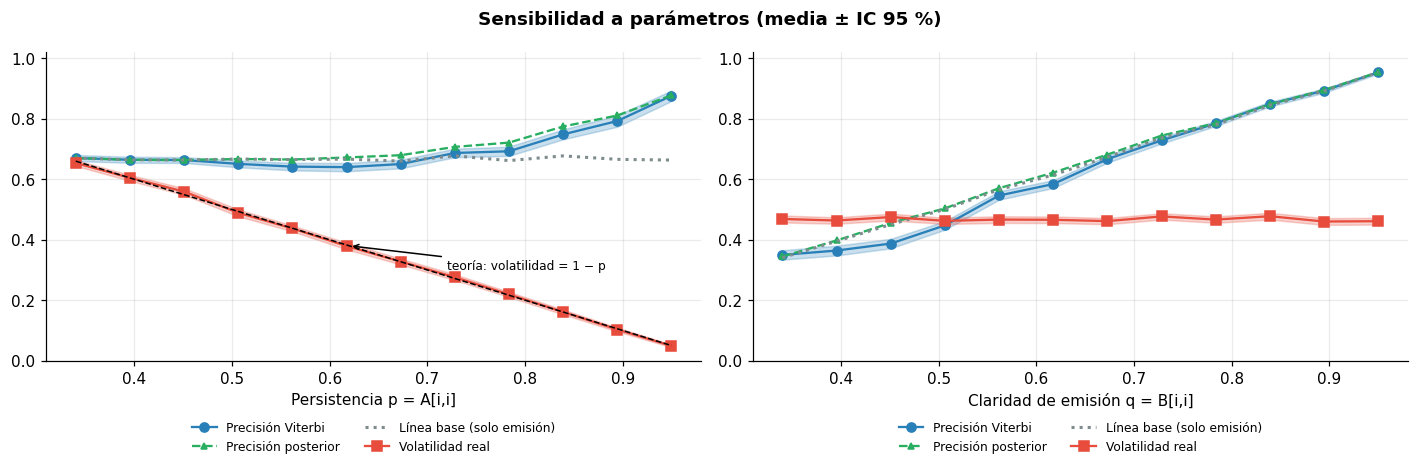

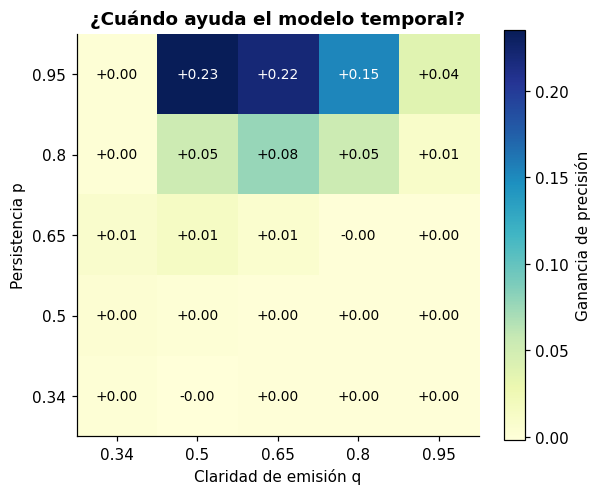

🎯 Sensibilidad a π · % esperado de estados positivos (exacto)


,π,T = 5,T = 30,T = 300
0,uniforme,33.33,33.33,33.33
1,"sesgo positivo (0.8,0.1,0.1)",49.49,36.10,33.61
2,"sesgo negativo (0.1,0.1,0.8)",22.36,31.43,33.14
3,"prompt original (0.4,0.4,0.2)",36.47,33.88,33.39


   → el efecto de π se disipa al crecer T: la cadena converge a su distribución estacionaria (33.3 %).


In [ ]:
# ============ 10. SENSIBILIDAD A p, q y π (P2 y P3) ============
def quick_eval(A, B, pi, tag, n_runs=300, T=30):
    out = []
    for r in range(n_runs):
        h = HMM(A, B, pi, seed=[SEED, *tag, r]); zz, oo = h.sample(T)
        out.append((np.mean(zz == h.viterbi(oo)[0]), np.mean(zz == h.decode_posterior(oo)), np.mean(zz == B.argmax(0)[oo]), vol(zz)))
    return np.array(out)

def persist(p): off = (1-p)/2; return np.full((3, 3), off) + np.eye(3)*(p-off), B0, PI0     # diagonal de A = p
def clarity(q): off = (1-q)/2; return A0, np.full((3, 3), off) + np.eye(3)*(q-off), PI0     # diagonal de B = q

def sweep(builder, grid, key):
    rows = []
    for gi, v in enumerate(grid):
        R = quick_eval(*builder(v), tag=(key, gi))
        rows.append([v, R[:, 0].mean(), *ci95(R[:, 0]), R[:, 1].mean(), R[:, 2].mean(), R[:, 3].mean(), *ci95(R[:, 3])])
    return pd.DataFrame(rows, columns=["valor", "acc_vit", "acc_lo", "acc_hi", "acc_post", "acc_base", "vol", "vol_lo", "vol_hi"])

grid = np.linspace(.34, .95, 12)
s1, s2 = sweep(persist, grid, 99), sweep(clarity, grid, 99)
s1.to_csv(f"{OUT}/sensibilidad_p.csv", index=False); s2.to_csv(f"{OUT}/sensibilidad_q.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, s, xl in [(axes[0], s1, "Persistencia p = A[i,i]"), (axes[1], s2, "Claridad de emisión q = B[i,i]")]:
    ax.plot(s.valor, s.acc_vit, "o-", color="#2980b9", label="Precisión Viterbi"); ax.fill_between(s.valor, s.acc_lo, s.acc_hi, color="#2980b9", alpha=.25)
    ax.plot(s.valor, s.acc_post, "^--", color="#27ae60", ms=4, label="Precisión posterior")
    ax.plot(s.valor, s.acc_base, ":", color="#7f8c8d", lw=2, label="Línea base (solo emisión)")
    ax.plot(s.valor, s.vol, "s-", color="#e74c3c", label="Volatilidad real"); ax.fill_between(s.valor, s.vol_lo, s.vol_hi, color="#e74c3c", alpha=.25)
    ax.set_xlabel(xl); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2, frameon=False)
axes[0].plot(grid, 1 - grid, "k--", lw=1)      # volatilidad teórica con A simétrica de diagonal p
axes[0].annotate("teoría: volatilidad = 1 − p", xy=(.62, .38), xytext=(.72, .3), arrowprops=dict(arrowstyle="->"), fontsize=8)
fig.suptitle("Sensibilidad a parámetros (media ± IC 95 %)", fontweight="bold")
plt.tight_layout(); savefig("fig7_sensibilidad"); plt.show()

# --- Mapa de calor: ¿dónde aporta el modelo temporal? (ganancia = precisión posterior − línea base) ---
gp = gq = np.array([.34, .50, .65, .80, .95]); G = np.zeros((5, 5))
for i, p in enumerate(gp):
    for j, q in enumerate(gq):
        A_, _, _ = persist(p); _, B_, _ = clarity(q)
        R = quick_eval(A_, B_, PI0, tag=(55, i, j), n_runs=100); G[i, j] = R[:, 1].mean() - R[:, 2].mean()
fig, ax = plt.subplots(figsize=(5.6, 4.6)); im = ax.imshow(G, origin="lower", cmap="YlGnBu")
for i in range(5):
    for j in range(5): ax.text(j, i, f"{G[i, j]:+.2f}", ha="center", va="center", fontsize=9, color="white" if G[i, j] > G.max()*.6 else "black")
ax.set_xticks(range(5)); ax.set_xticklabels(gq); ax.set_yticks(range(5)); ax.set_yticklabels(gp); ax.grid(False)
ax.set_xlabel("Claridad de emisión q"); ax.set_ylabel("Persistencia p"); plt.colorbar(im, label="Ganancia de precisión")
ax.set_title("¿Cuándo ayuda el modelo temporal?", fontweight="bold"); plt.tight_layout(); savefig("fig8_ganancia_pq"); plt.show()

# --- Sensibilidad a π (condición inicial): cálculo EXACTO, sin simulación: E[% positivo] = (1/T) Σ_t π A^(t-1) ---
def expected_pct(pi0, T, A=A0):
    d, acc = np.array(pi0, float), np.zeros(3)
    for _ in range(T): acc += d; d = d @ A
    return acc / T * 100
rows = []
for name, p0 in {"uniforme": [1/3]*3, "sesgo positivo (0.8,0.1,0.1)": [.8, .1, .1], "sesgo negativo (0.1,0.1,0.8)": [.1, .1, .8], "prompt original (0.4,0.4,0.2)": PI0}.items():
    rows.append([name] + [expected_pct(p0, TT)[0] for TT in (5, 30, 300)])
print("🎯 Sensibilidad a π · % esperado de estados positivos (exacto)")
show(pd.DataFrame(rows, columns=["π", "T = 5", "T = 30", "T = 300"]).round(2))
print("   → el efecto de π se disipa al crecer T: la cadena converge a su distribución estacionaria (33.3 %).")

🧠 Baum-Welch · 20 reinicios × 300 iteraciones · 6000 observaciones
   log-verosimilitud: mejor reinicio = -6470.1 | peor = -6475.9 | modelo VERDADERO sobre los mismos datos = -6473.9
   Δ última iteración (mejor) = 4.15e-03
   Error absoluto medio del mejor reinicio → A: 0.0493 | B: 0.0714 | π: 0.0849
   Dispersión del error en B entre reinicios: mín 0.053 · máx 0.155
   ℹ️ El aprendido alcanza ≥ verosimilitud que el modelo verdadero: las diferencias con B vienen de identificabilidad débil/ruido muestral, no de mala optimización.

A aprendida:
           Positivo  Neutral  Negativo
Positivo     0.685    0.220     0.095
Neutral      0.343    0.440     0.217
Negativo     0.092    0.254     0.654

B aprendida:
           Alegre  Normal  Triste
Positivo   0.679   0.248   0.073
Neutral    0.009   0.598   0.394
Negativo   0.179   0.197   0.623


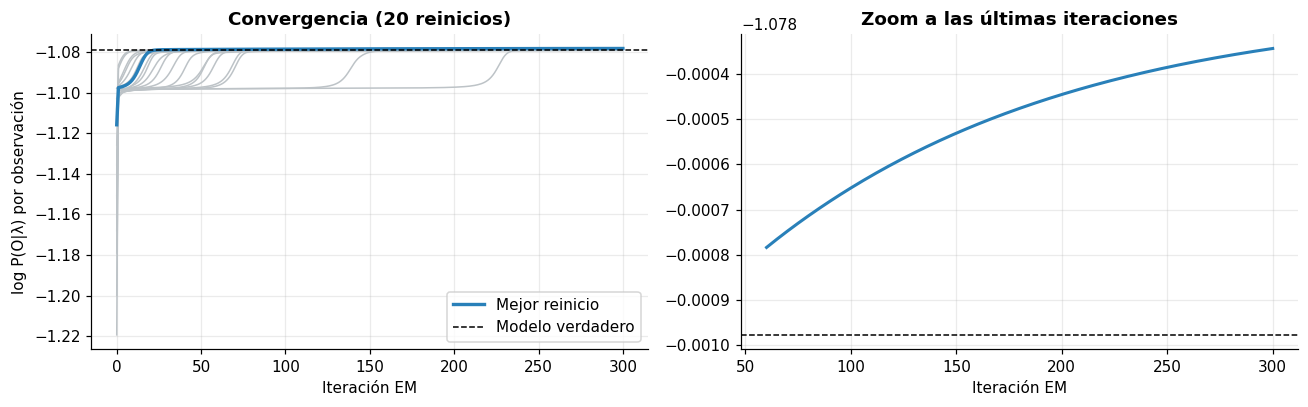

In [ ]:
# ============ 11. APRENDIZAJE: BAUM-WELCH CON VARIOS REINICIOS ============
def align(model, ref):
    """Alinea los estados aprendidos con los reales (permutación que minimiza |B_aprendida − B_real|)."""
    best = min(itertools.permutations(range(3)), key=lambda p: np.abs(model.B[list(p)] - ref.B).sum())
    p = list(best); return HMM(model.A[np.ix_(p, p)], model.B[p], model.pi[p])

gen = HMM(A0, B0, PI0, seed=SEED)
train = np.array([gen.sample(30)[1] for _ in range(200)])               # 200 secuencias × 30 palabras (solo observaciones)
true_ll = HMM(A0, B0, PI0).loglik(train)
rng_init = np.random.default_rng(SEED); N_RESTARTS = 20; res = []
for k in range(N_RESTARTS):                                              # el reinicio 0 coincide con una sola inicialización Dirichlet
    init = HMM(rng_init.dirichlet(np.ones(3)*3, 3), rng_init.dirichlet(np.ones(3)*3, 3), rng_init.dirichlet(np.ones(3)*3))
    m, hist = baum_welch(train, init.A, init.B, init.pi, n_iter=300)
    m = align(m, HMM(A0, B0, PI0)); res.append((hist[-1], m, hist))
res.sort(key=lambda r: -r[0]); best_ll, learned, best_hist = res[0]

err = lambda m: (np.abs(m.A-A0).mean(), np.abs(m.B-B0).mean(), np.abs(m.pi-PI0).mean())
print(f"🧠 Baum-Welch · {N_RESTARTS} reinicios × 300 iteraciones · {train.size} observaciones")
print(f"   log-verosimilitud: mejor reinicio = {best_ll:.1f} | peor = {res[-1][0]:.1f} | modelo VERDADERO sobre los mismos datos = {true_ll:.1f}")
print(f"   Δ última iteración (mejor) = {best_hist[-1]-best_hist[-2]:.2e}")
eA, eB, ePi = err(learned); print(f"   Error absoluto medio del mejor reinicio → A: {eA:.4f} | B: {eB:.4f} | π: {ePi:.4f}")
print(f"   Dispersión del error en B entre reinicios: mín {min(err(r[1])[1] for r in res):.3f} · máx {max(err(r[1])[1] for r in res):.3f}")
if best_ll >= true_ll: print("   ℹ️ El aprendido alcanza ≥ verosimilitud que el modelo verdadero: las diferencias con B vienen de identificabilidad débil/ruido muestral, no de mala optimización.")
print("\nA aprendida:\n", pd.DataFrame(learned.A, index=SHORT, columns=SHORT).round(3))
print("\nB aprendida:\n", pd.DataFrame(learned.B, index=SHORT, columns=["Alegre", "Normal", "Triste"]).round(3))
pd.DataFrame([[i, r[0], *err(r[1])] for i, r in enumerate(res)], columns=["rank", "loglik", "err_A", "err_B", "err_pi"]).to_csv(f"{OUT}/baum_welch_reinicios.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for r in res[1:]: axes[0].plot(r[2]/train.size, color="#bdc3c7", lw=1)
axes[0].plot(best_hist/train.size, color="#2980b9", lw=2.2, label="Mejor reinicio"); axes[0].axhline(true_ll/train.size, color="k", ls="--", lw=1, label="Modelo verdadero")
axes[0].set_xlabel("Iteración EM"); axes[0].set_ylabel("log P(O|λ) por observación"); axes[0].legend(); axes[0].set_title("Convergencia (20 reinicios)", fontweight="bold")
axes[1].plot(np.arange(60, len(best_hist)), best_hist[60:]/train.size, color="#2980b9", lw=2); axes[1].axhline(true_ll/train.size, color="k", ls="--", lw=1)
axes[1].set_xlabel("Iteración EM"); axes[1].set_title("Zoom a las últimas iteraciones", fontweight="bold")
plt.tight_layout(); savefig("fig9_baumwelch"); plt.show()

In [ ]:
# ============ 12. EXPORTAR EVIDENCIA PARA EL REPOSITORIO ============
df.to_csv(f"{OUT}/simulacion_base_30_tweets.csv", index=False)
with open(f"{OUT}/entorno.txt", "w") as f:
    f.write("\n".join(f"{k} {v}" for k, v in ENV.items()) + "\n")
print("📁 Archivos generados en ./resultados:", sorted(os.listdir(OUT)))
try:
    from google.colab import files; import shutil
    shutil.make_archive("resultados", "zip", OUT); files.download("resultados.zip")
except ImportError:
    pass

📁 Archivos generados en ./resultados: ['baum_welch_reinicios.csv', 'entorno.txt', 'fig0_matrices.png', 'fig1_timeline.png', 'fig2_nubes.png', 'fig3_evolucion.png', 'fig4_pie_rachas.png', 'fig5_escenarios.png', 'fig6_decodificadores.png', 'fig7_sensibilidad.png', 'fig8_ganancia_pq.png', 'fig9_baumwelch.png', 'resultados_crudos.csv', 'resumen_estadistico.csv', 'sensibilidad_p.csv', 'sensibilidad_q.csv', 'simulacion_base_30_tweets.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>